In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
df = pd.read_csv("/Users/mbouch17/Downloads/amz_uk_price_prediction_dataset.csv")

#----------------------------------------------------#

df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

1. Crosstab Analysis:

    Create a crosstab between the product category and the isBestSeller status.

    Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

2. Statistical Tests:

    Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    Compute Cramér's V to understand the strength of association between best-seller status and category.
3. Visualizations:

    Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

### Question 1

In [5]:
# Generating a crosstab for 'MSZoning' and 'SaleCondition'
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [6]:
# Sort the crosstab by the 'True' column in descending order
sorted_crosstab = crosstab_result.sort_values(by=True, ascending=False)
sorted_crosstab


Best-seller are more prevalent in 'Grocery' and 'Health & Personal Care categories'.

SyntaxError: invalid syntax (1481105634.py, line 6)

### Question 2

In [ ]:
from scipy.stats import chi2_contingency

# Chi-square test for 'isBestSeller' and 'category'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(sorted_crosstab)

chi2_statistic, chi2_p_value

In [ ]:
#p.value being lower than 0.05 We can not assume that there is a relation between 'isBestSeller', 'category'. In other words, there is potentially a relation between these 2 columns.

In [ ]:
from scipy.stats.contingency import association

# Computing the association between variables in 'isBestSeller' using the "isBestSeller" method
association(sorted_crosstab, method="cramer")

In [ ]:
# The Cramér's V value of 0.122 suggests a weak association between the two variables. 
# Though statistically significant, the strength of this relationship is not very strong in practical terms.

## Question 3

In [ ]:
# Plotting a stacked bar chart for the 'sorted_crosstab' data
sorted_crosstab.plot(kind="bar", stacked=True)

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

0. Preliminary Step: Remove outliers in product prices.

    For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

    Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

1. Violin Plots:

    Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.
Bar Charts:

2. Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.
Box Plots:

3. Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.


## Question 0

In [ ]:
def remove_price_outliers(df):
    # Calculate Q1 and Q3
    Q1 = df['price'].quantile(0.25)
    Q3 = df['price'].quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Filter the dataframe to remove outliers
    df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

    return df_no_outliers

# Example usage
df_cleaned = remove_price_outliers(df)

remove_price_outliers(df)

## Question 1

In [ ]:
sns.violinplot(data=df, x='category', y='price', palette="coolwarm")

In [ ]:
# Get the top 20 categories based on count
top_20_categories = df['category'].value_counts().nlargest(20).index
df_top_20 = df[df['category'].isin(top_20_categories)]

# Create the violin plot
plt.figure(figsize=(12, 8))
sns.violinplot(data=df_top_20, x='price', y='category', palette="coolwarm")

plt.xticks(rotation=90)
plt.title('Violin Plot of Price Distribution for Top 20 Categories')
plt.xlabel('Price')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

## Question 2

In [ ]:
# Create a bar chart comparing the average price of products for the top 10 product categories (based on count). 
# Which product category commands the highest average price? Don't filter here by top categories. Box Plots:

In [ ]:
# Get top 10 categories based on count
top_10_categories = df['category'].value_counts().nlargest(10).index

# Calculate average price for each category
avg_prices = df[df['category'].isin(top_10_categories)].groupby('category')['price'].mean().sort_values(ascending=False)

# Create bar plot
plt.figure(figsize=(12, 6))
sns.barplot(x=avg_prices.values, y=avg_prices.index)
plt.title('Average Price by Top 10 Product Categories')
plt.xlabel('Average Price ($)')
plt.ylabel('Category')

## Question 3

In [ ]:
#Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization. 
#Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [ ]:
# Get top 10 categories based on count
top_10_categories = df['category'].value_counts().nlargest(10).index

# Calculate average price for each category 
avg_prices = df[df['category'].isin(top_10_categories)].groupby('category')['price'].mean().sort_values(ascending=False)

# Create bar chart
plt.figure(figsize=(12, 6))
plt.barh(avg_prices.index, avg_prices.values)
plt.title('Average Price by Top 10 Product Categories')
plt.xlabel('Average Price ($)')
plt.ylabel('Category')

## Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

Correlation Coefficients:

1. Calculate the correlation coefficient between price and stars.
    Is there a significant correlation between product price and its rating?
   
3. Visualizations:
    Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    Use a correlation heatmap to visualize correlations between all numerical variables.
    Examine if product prices typically follow a normal distribution using a QQ plot.

## Question 1

In [10]:
# Calculating the Pearson correlation coefficient between 'price' and 'stars' columns
correlation = df['price'].corr(df['stars'])
correlation

-0.12490673262148386

In [ ]:
# The Pearson correlation of (-0.1249) suggests a weak negative linear relationship between the price of a book and its Amanzon rating. In other words, rating is not a good indicator of price.

## Question 2

<Axes: xlabel='stars', ylabel='price'>

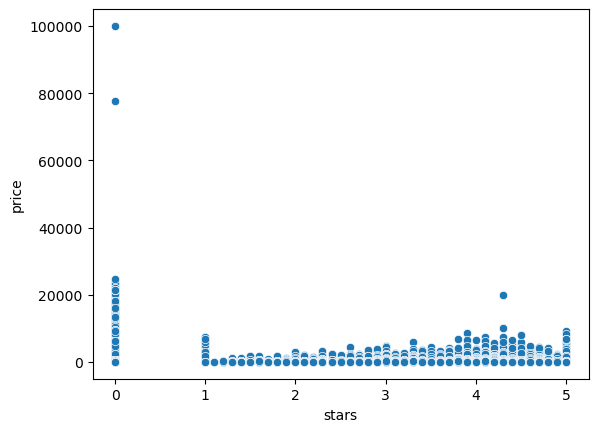

In [17]:
sns.scatterplot(data=df, x='stars', y='price')

In [30]:
# Select only numerical columns
numerical_cols = df.select_dtypes(include=[np.number]).columns


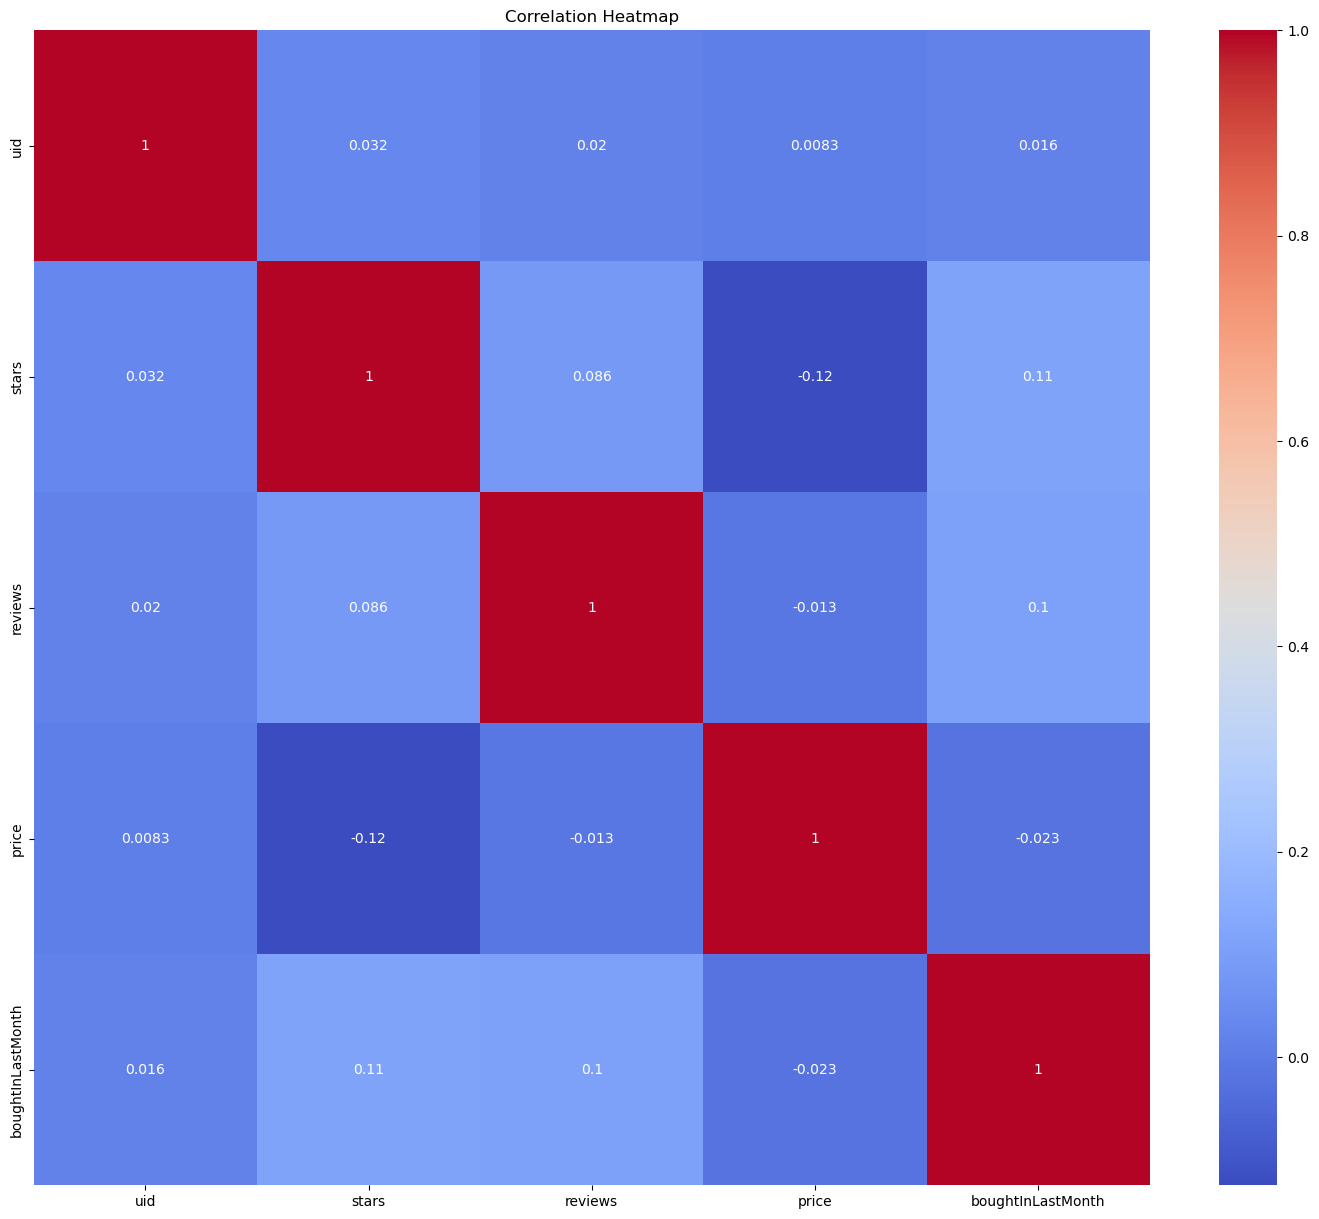

In [32]:
correlation_matrix = df[numerical_cols].corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

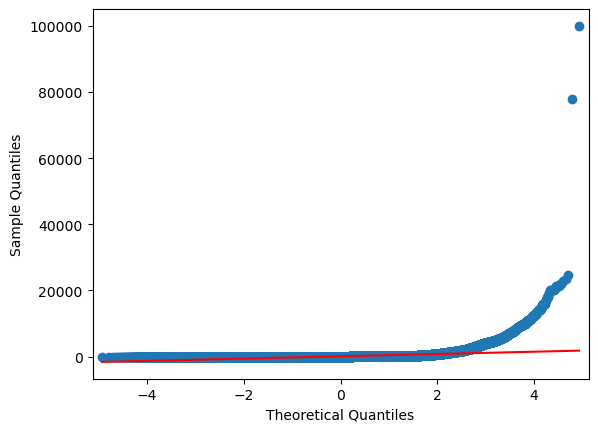

In [35]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'price' to check if its distribution follows a normal distribution
sm.qqplot(df['price'], line='s');

In [ ]:
# Upper Tail: In the upper tail (right side of the plot), the data points deviate significantly from the red line, suggesting a long tail or skewness to the right. 
# This indicates that there are more extreme high values in SalePrice than would be expected in a normal distribution.